# Objective 5 — Explanatory importance and temporal stability of reporting indicators (SHAP)

**Objective.** Examine which financial-reporting indicators drive predicted misstatement risk, whether their importance and direction are stable over time, and what this implies for risk-based forensic auditing and regulatory monitoring.

**Design.**
* XGBoost refitted for each test year with the rolling design of Objectives 1–2 (Compustat, 42 inputs, recoded AAER labels, 2003–2014) and Objective 3 (XBRL, 40 inputs, restatement labels, 2013–2024).
* TreeSHAP values on each test year's firms; importance = mean |SHAP|.
* Stability: Spearman correlation of importance rankings between years, top-10 overlap (Jaccard), and the sign of the value–SHAP relation.
* Size confound check: a **size-neutral** model in which every raw item is scaled by total assets and size measures (total assets, shares, price) are removed.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from misstatement.config import *
from misstatement import data, metrics, models, plots
plots.style()
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.precision', 3)
import shap
from scipy.stats import spearmanr
from misstatement import fsds

In [2]:
def shap_by_year(d, cols, years, y_col, firm_col, treat, aaer_col='p_aaer', label_date_col=None):
    imp, dirn, store = {}, {}, {}
    for T in years:
        tr, te = d[d.fyear <= T - GAP], d[d.fyear == T]
        y, keep = models.training_labels(tr, te, treat, y_col, aaer_col, firm_col)
        if label_date_col:
            y = np.where((pd.to_datetime(tr[label_date_col]) <= pd.Timestamp(f'{T}-12-31')).values, y, 0)
        m = models.make_model('XGB'); m.fit(tr[keep][cols].values.astype(float), y[keep])
        Xte = te[cols].astype(float)
        sv = shap.TreeExplainer(m).shap_values(Xte.values)
        imp[T] = pd.Series(np.abs(sv).mean(0), index=cols)
        dirn[T] = pd.Series([spearmanr(Xte[c], sv[:, i], nan_policy='omit')[0] for i, c in enumerate(cols)], index=cols)
        store[T] = (sv, Xte)
    return pd.DataFrame(imp), pd.DataFrame(dirn), store

def stability(imp, k=10):
    yrs = imp.columns
    rho = pd.DataFrame([[spearmanr(imp[a], imp[b])[0] for b in yrs] for a in yrs], index=yrs, columns=yrs)
    top = {t: set(imp[t].nlargest(k).index) for t in yrs}
    jac = pd.DataFrame([[len(top[a] & top[b]) / len(top[a] | top[b]) for b in yrs] for a in yrs], index=yrs, columns=yrs)
    adj = pd.Series([rho.iloc[i, i + 1] for i in range(len(yrs) - 1)], index=yrs[1:])
    return rho, jac, adj

## 1. Compustat / AAER model, 2003–2014

In [3]:
bao = data.load_bao()
COLS = data.RAW28 + data.RAT14
imp_b, dir_b, store_b = shap_by_year(bao, COLS, BAO_TEST_YEARS + LATE_TEST_YEARS, 'misstate', 'gvkey', 'recode')
rank_b = imp_b.rank(ascending=False).astype(int)
rho_b, jac_b, adj_b = stability(imp_b)
imp_b.to_csv(TABLES / 'T24_obj5_shap_importance_compustat.csv'); dir_b.to_csv(TABLES / 'T25_obj5_shap_direction_compustat.csv')
rho_b.to_csv(TABLES / 'T26_obj5_rank_stability_compustat.csv')
print('Spearman between adjacent years:', adj_b.round(2).to_dict())
print(f'Spearman 2003 vs 2014: {rho_b.loc[2003, 2014]:.2f}; top-10 Jaccard 2003 vs later years: {jac_b.loc[2003].iloc[1:].min():.2f}-{jac_b.loc[2003].iloc[1:].max():.2f}')
order = imp_b.mean(axis=1).sort_values(ascending=False).index
tab = rank_b.loc[order[:15]].copy(); tab.insert(0, 'label', [data.LABELS[c] for c in tab.index])
tab['direction (median rho)'] = dir_b.loc[order[:15]].median(axis=1).round(2)
tab

Spearman between adjacent years: {2004: 0.79, 2005: 0.93, 2006: 0.89, 2007: 0.91, 2008: 0.96, 2009: 0.95, 2010: 0.94, 2011: 0.93, 2012: 0.96, 2013: 0.95, 2014: 0.97}
Spearman 2003 vs 2014: 0.69; top-10 Jaccard 2003 vs later years: 0.43-0.54


,label,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,direction (median rho)
soft_assets,Soft assets,1,1,1,1,1,1,1,1,1,1,1,1,0.96
reoa,RE / assets,2,2,2,2,3,4,3,2,2,2,3,2,0.31
sstk,Equity issued,3,3,3,3,2,2,2,3,3,4,6,6,0.87
prcc_f,Share price,5,4,4,4,4,5,5,5,5,5,4,3,0.95
ceq,Common equity,13,6,6,6,5,3,4,4,4,3,2,4,0.85
dp,Depreciation & amort.,4,5,5,5,6,6,6,6,6,6,5,5,-0.73
act,Current assets,9,8,9,7,7,7,7,7,7,7,7,7,0.36
bm,Book-to-market,11,7,7,9,11,9,10,9,11,13,11,13,-0.55
ppegt,Gross PP&E,7,14,11,23,13,11,8,10,9,8,10,8,-0.60
EBIT,EBIT / assets,25,10,8,8,9,8,13,13,14,9,13,11,-0.56


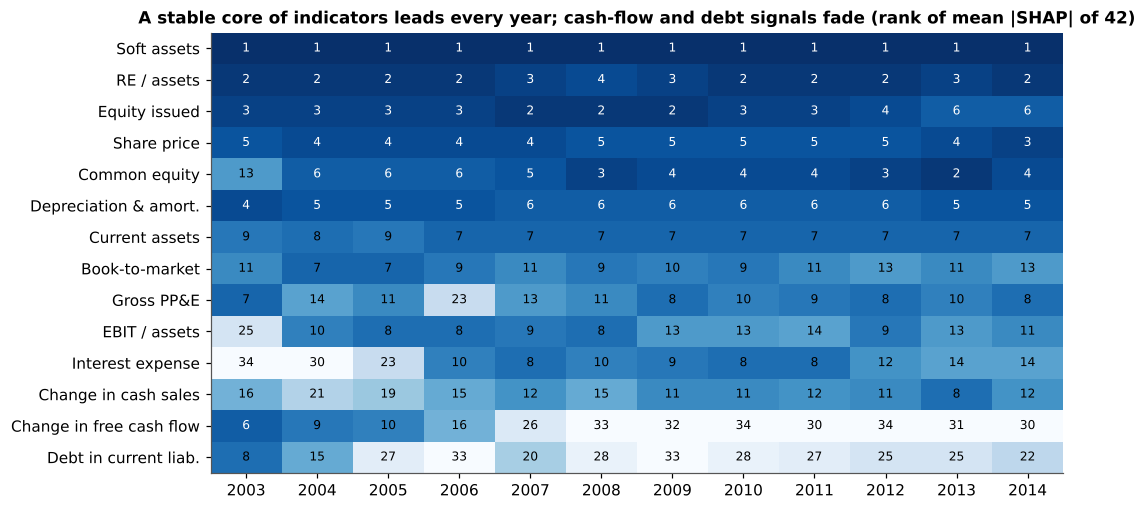

In [4]:
top = list(order[:12]) + [c for c in ('ch_fcf', 'dlc') if c not in order[:12]]
R = rank_b.loc[top]
fig, ax = plt.subplots(figsize=(10, 5.2))
im = ax.imshow(np.minimum(R.values, 30), cmap='Blues_r', vmin=1, vmax=30, aspect='auto')
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        ax.text(j, i, R.values[i, j], ha='center', va='center', fontsize=8, color='white' if R.values[i, j] <= 6 else 'black')
ax.set_xticks(range(R.shape[1])); ax.set_xticklabels(R.columns); ax.set_yticks(range(R.shape[0]))
ax.set_yticklabels([data.LABELS[c] for c in R.index]); ax.grid(False)
ax.set_title('A stable core of indicators leads every year; cash-flow and debt signals fade (rank of mean |SHAP| of 42)')
plots.save(fig, 'F09_obj5_shap_rank_heatmap'); plt.show()

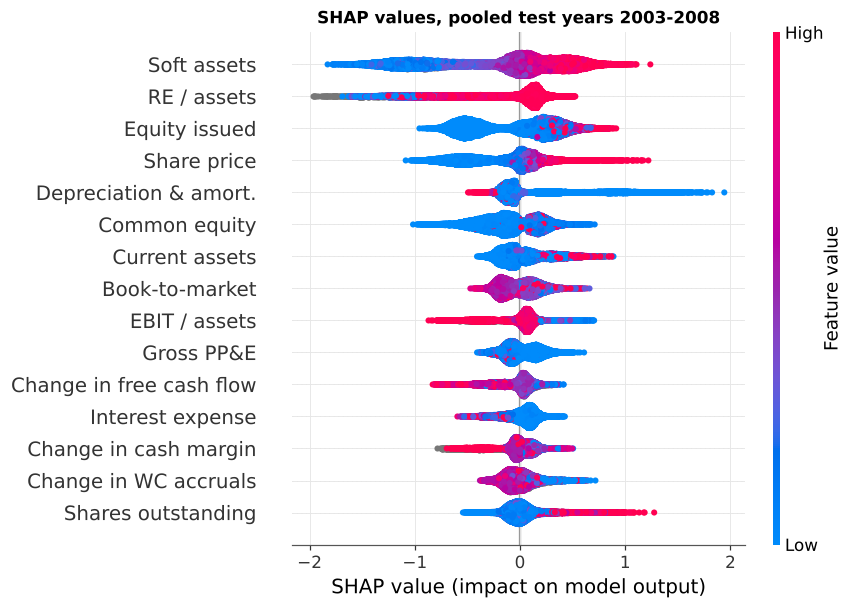

In [5]:
sv = np.vstack([store_b[t][0] for t in BAO_TEST_YEARS]); Xp = pd.concat([store_b[t][1] for t in BAO_TEST_YEARS])
plt.figure()
shap.summary_plot(sv, Xp.rename(columns=data.LABELS), max_display=15, show=False, plot_size=(8, 5.5))
plt.title('SHAP values, pooled test years 2003-2008'); plots.save(plt.gcf(), 'F10_obj5_shap_beeswarm'); plt.show()

## 2. Size confound: correlation of each driver with firm size, and a size-neutral model

In [6]:
la = np.log1p(bao['at'].clip(lower=0))
size_corr = pd.Series({c: spearmanr(bao[c], la, nan_policy='omit')[0] for c in order[:10]}).round(2)
print('Spearman correlation with log total assets:'); print(size_corr.to_string())
mis = bao.groupby('misstate')[['at', 'sale', 'sstk']].median().T; mis.columns = ['other firm-years', 'AAER firm-years']; display(mis.round(1))

# Size-neutral inputs: raw items divided by total assets; size, shares and price removed
SN = [c for c in data.RAW28 if c not in ('at', 'csho', 'prcc_f')]
bz = bao.copy()
for c in SN: bz[f'{c}_at'] = bz[c] / bz['at'].replace(0, np.nan)
SN_COLS = [f'{c}_at' for c in SN] + data.RAT14
sn_pred = models.cached(CACHE / 'obj5_size_neutral_predictions.parquet', models.rolling, bz, [('XGB', 'sn', 'recode')],
                        BAO_TEST_YEARS + LATE_TEST_YEARS, {'sn': SN_COLS}, verbose=False)
o2 = pd.read_parquet(CACHE / 'obj2_predictions_a.parquet')
ref = o2[(o2.model == 'XGB') & (o2.fset == 'all') & (o2.seed == 42)]
siz = o2[(o2.model == 'Size') & (o2.seed == 42)]
cmpt = pd.DataFrame({k: [metrics.summarise(metrics.per_year(v, ['model']), ['model'], w).iloc[0].auc for w in (BAO_TEST_YEARS, LATE_TEST_YEARS)]
                     for k, v in {'XGB, 42 inputs': ref, 'XGB, size-neutral inputs': sn_pred, 'Size only': siz}.items()},
                    index=['AUC 2003-08', 'AUC 2009-14']).T
cmpt.to_csv(TABLES / 'T27_obj5_size_neutral.csv'); cmpt.round(3)

Spearman correlation with log total assets:
soft_assets    0.04
reoa           0.57
sstk           0.37
prcc_f         0.76
ceq            0.89
dp             0.93
act            0.96
bm             0.22
ppegt          0.93
EBIT           0.45


,other firm-years,AAER firm-years
at,106.5,500.5
sale,89.3,412.9
sstk,0.7,5.8


,AUC 2003-08,AUC 2009-14
"XGB, 42 inputs",0.702,0.711
"XGB, size-neutral inputs",0.677,0.705
Size only,0.641,0.658


In [7]:
imp_sn, dir_sn, _ = shap_by_year(bz, SN_COLS, BAO_TEST_YEARS, 'misstate', 'gvkey', 'recode')
sn_rank = imp_sn.mean(axis=1).sort_values(ascending=False).head(10)
pd.DataFrame({'mean |SHAP|': sn_rank.round(4), 'direction': dir_sn.loc[sn_rank.index].median(axis=1).round(2)})

,mean |SHAP|,direction
sstk_at,0.344,0.81
ppegt_at,0.309,-0.93
soft_assets,0.298,0.92
re_at,0.242,0.56
bm,0.240,-0.89
dp_at,0.223,-0.81
sale_at,0.219,-0.37
reoa,0.210,0.63
che_at,0.204,-0.64
xint_at,0.167,-0.43


## 3. XBRL / restatement model, 2013–2024

In [8]:
P = pd.read_parquet(DATA_PROCESSED / 'xbrl_panel.parquet'); Rr = pd.read_parquet(DATA_PROCESSED / 'xbrl_restatements.parquet')
P = P.merge(Rr[['cik', 'fyear', 'filed_a']], on=['cik', 'fyear'], how='left'); P['restated'] = P.filed_a.notna().astype(int)
X = P[P.spac == 0].reset_index(drop=True)
XC = data.RAW27 + fsds.XRATIOS
XL = {**data.LABELS, 'x_dch_wc': 'Change in WC accruals', 'x_dch_rec': 'Change in receivables', 'x_dch_inv': 'Change in inventory',
      'x_soft_assets': 'Soft assets', 'x_ch_roa': 'Change in ROA', 'x_tacc': 'Total accruals', 'x_issue': 'Securities issuance',
      'x_reoa': 'RE / assets', 'x_ebit': 'EBIT / assets', 'x_ch_sale': 'Sales growth', 'x_loss': 'Loss indicator',
      'x_lev': 'Leverage', 'x_size': 'Log total assets'}
imp_x, dir_x, _ = shap_by_year(X, XC, list(range(2013, 2025)), 'restated', 'cik', 'firm_excl', aaer_col='cik', label_date_col='filed_a')
rho_x, jac_x, adj_x = stability(imp_x)
imp_x.to_csv(TABLES / 'T28_obj5_shap_importance_xbrl.csv'); rho_x.to_csv(TABLES / 'T29_obj5_rank_stability_xbrl.csv')
print('Spearman between adjacent years:', adj_x.round(2).to_dict())
ox = imp_x.mean(axis=1).sort_values(ascending=False).index[:12]
tx = imp_x.rank(ascending=False).astype(int).loc[ox]; tx.insert(0, 'label', [XL[c] for c in ox])
tx['direction (median rho)'] = dir_x.loc[ox].median(axis=1).round(2); tx

Spearman between adjacent years: {2014: 0.51, 2015: 0.8, 2016: 0.9, 2017: 0.88, 2018: 0.91, 2019: 0.92, 2020: 0.95, 2021: 0.93, 2022: 0.87, 2023: 0.92, 2024: 0.96}


,label,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,direction (median rho)
act,Current assets,25,1,2,1,1,2,3,3,1,2,2,2,-0.49
ni,Net income,28,19,7,3,10,7,8,8,3,1,1,1,-0.85
x_ch_sale,Sales growth,4,4,3,2,2,5,4,9,11,8,6,5,0.36
cogs,Cost of goods sold,20,16,1,5,3,1,1,2,2,9,16,13,-0.40
x_soft_assets,Soft assets,21,5,15,13,8,4,2,1,4,5,5,11,0.66
x_ch_roa,Change in ROA,18,12,4,7,7,8,9,4,10,4,8,4,-0.01
x_reoa,RE / assets,16,25,9,12,5,6,7,6,9,6,3,3,0.57
x_dch_rec,Change in receivables,9,11,5,6,16,3,6,7,8,13,10,10,0.23
lct,Current liabilities,10,10,6,8,11,9,5,10,6,3,13,12,0.36
x_tacc,Total accruals,2,2,10,20,17,14,13,16,7,12,15,15,-0.61


In [9]:
stab = pd.DataFrame({
    'sample': ['Compustat/AAER 2003-14', 'XBRL/restatement 2013-24'],
    'adjacent-year Spearman (min)': [adj_b.min(), adj_x.min()], 'adjacent-year Spearman (median)': [adj_b.median(), adj_x.median()],
    'first vs last year Spearman': [rho_b.iloc[0, -1], rho_x.iloc[0, -1]],
    'top-10 Jaccard first vs last': [jac_b.iloc[0, -1], jac_x.iloc[0, -1]]})
stab.to_csv(TABLES / 'T30_obj5_stability_summary.csv', index=False); stab.round(2)

,sample,adjacent-year Spearman (min),adjacent-year Spearman (median),first vs last year Spearman,top-10 Jaccard first vs last
0,Compustat/AAER 2003-14,0.79,0.94,0.69,0.54
1,XBRL/restatement 2013-24,0.51,0.91,0.52,0.25


## Findings for Objective 5

* In the Compustat model a small core — soft assets, equity issuance, retained earnings to assets, depreciation and share price — ranks near the top in every year, with stable direction (higher soft assets and issuance raise predicted risk). Change in free cash flow and short-term debt lose importance after the mid-2000s.
* Importance rankings are highly correlated between adjacent years but drift over a decade, so explanations should be re-estimated whenever the model is retrained.
* Several leading drivers are strongly correlated with firm size, and AAER firm-years are several times larger than other firms. A size-neutral model keeps most of the discrimination, but its leading drivers differ: part of what SHAP attributes to "accounting signals" in raw-item models is the SEC's enforcement focus on large, capital-raising firms.
* In the XBRL restatement model the drivers differ from the AAER model (see table), consistent with restatements capturing a broader, less size-selected set of reporting failures.
* Implication for audit and regulators: SHAP rankings are useful for explaining why a firm is flagged and for monitoring drift, but they are not causal evidence of manipulation and should not be used as fixed red-flag checklists.